# Smart Fall Risk Detection Using Machine Learning

## 1. Project Overview

Falls can pose serious risks, particularly for elderly individuals. Machine learning can be explored to analyze relevant sensor and physiological features and classify samples into different decision categories.

This project implements and compares three machine learning algorithms—Decision Tree, Random Forest, and Support Vector Machine (SVM)—using the `cStick_realistic.csv` dataset.

## 2. Project Objectives

- Explore and analyze the dataset, its features, and target classes.
- Identify and handle missing values through median imputation.
- Train three machine learning classification algorithms using a consistent data split.
- Evaluate the models using accuracy, precision, recall, and F1-score.
- Analyze model predictions using confusion matrices, ROC curves, and precision–recall curves.
- Examine feature importance, learning curves, and relationships between input features.
- Compare the models and select the best-performing candidate for further development.

## 3. Dataset Description

The dataset contains six input features:

1. Distance
2. Pressure
3. HRV
4. Sugar level
5. SpO2
6. Accelerometer

The target variable is `Decision`, containing three classes: 0, 1, and 2. The exact meaning of each class depends on the dataset's documentation.

The dataset contains missing values in several input features, which are addressed during preprocessing.

## 4. Data Preprocessing

The dataset is separated into input features (`X`) and the target variable (`y`). It is then divided into training and testing sets using an 80:20 split with stratification to preserve the class distribution.

Missing input values are handled using median imputation. The imputer is fitted on the training data and then applied to both training and testing data to avoid using test-set information during preprocessing.

For SVM, feature standardization is included in a pipeline so that scaling is fitted on the training data during model training.

## 5. Machine Learning Models

### 5.1 Decision Tree

A Decision Tree classifier is trained to learn decision rules from the input features and predict the target class.

### 5.2 Random Forest

A Random Forest classifier using 100 decision trees is trained to combine predictions from multiple trees and improve classification performance.

### 5.3 Support Vector Machine (SVM)

An SVM classifier is trained using standardized input features to identify decision boundaries between the target classes.

## 6. Model Evaluation and Visualization

The three models are evaluated using the same test set. The following metrics and visualizations are used:

- Accuracy comparison to summarize overall model performance.
- Classification reports containing precision, recall, and F1-score.
- Confusion matrices to examine correct and incorrect class predictions.
- ROC curves and AUC values to evaluate class discrimination.
- Precision–recall curves to examine the precision–recall trade-off.
- Feature-importance plots for Decision Tree and Random Forest.
- Permutation feature importance for SVM.
- Learning curves to compare training and cross-validation performance as training data increases.
- A correlation heatmap to visualize relationships among input features.
- Class-distribution and missing-value graphs to support dataset analysis and preprocessing.

## 7. Model Selection

The models are compared using their test accuracy and other evaluation metrics. The model with the highest observed test accuracy is selected as the candidate for subsequent stages, while class-wise performance and generalization must also be considered.


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
df_realistic = pd.read_csv(
    r"C:\Users\nashv\Documents\smart_fall_risk_project\data\cStick_realistic.csv"
)

df_realistic.head()

,Distance,Pressure,HRV,Sugar level,SpO2,Accelerometer,Decision
0,21.65,-2.35,100.04,61.63,88.66,1.14,1
1,1.07,4.21,109.12,50.00,72.00,1.07,2
2,67.17,-1.38,89.63,80.65,100.00,0.26,0
3,11.94,NaN,89.82,50.00,84.29,1.32,1
4,69.77,0.59,NaN,79.57,99.57,0.08,0


In [14]:
print("Dataset shape:", df_realistic.shape)
print("\nMissing values:")
print(df_realistic.isnull().sum())

Dataset shape: (2039, 7)

Missing values:
Distance         38
Pressure         56
HRV              49
Sugar level      48
SpO2             54
Accelerometer     0
Decision          0
dtype: int64


In [15]:

# Investigate the suspiciously high accuracy
# observed in the original dataset.

valid = (
    df_realistic["SpO2"].notna()
    & df_realistic["Distance"].notna()
)

spo2 = df_realistic["SpO2"]
distance = df_realistic["Distance"]

rule_pred_realistic = np.select(
    [
        (spo2 <= 89.99) & (distance <= 9.99),
        (spo2 <= 89.99) & (distance > 9.99),
        spo2 > 89.99
    ],
    [2, 1, 0],
    default=-1
)

correct = (
    df_realistic.loc[valid, "Decision"].to_numpy()
    == rule_pred_realistic[valid]
).sum()

total = valid.sum()

print("Rows checked:", total)
print("Correct rule matches:", correct)
print("Rule agreement:", round(correct / total * 100, 2), "%")
print("Rows not explained by this rule:", total - correct)


Rows checked: 1947
Correct rule matches: 1706
Rule agreement: 87.62 %
Rows not explained by this rule: 241


In [16]:
print("Missing values:")
print(df_realistic.isnull().sum())

print("\nDecision class distribution:")
print(df_realistic["Decision"].value_counts().sort_index())

Missing values:
Distance         38
Pressure         56
HRV              49
Sugar level      48
SpO2             54
Accelerometer     0
Decision          0
dtype: int64

Decision class distribution:
Decision
0    696
1    683
2    660
Name: count, dtype: int64


In [17]:

# Check exact duplicate rows
print("Exact duplicate rows:",
      df_realistic.duplicated().sum())

# Check duplicate feature combinations
feature_cols = [
    col for col in df_realistic.columns
    if col != "Decision"
]

duplicate_features = df_realistic.duplicated(
    subset=feature_cols,
    keep=False
)

print(
    "Rows sharing identical features:",
    duplicate_features.sum()
)

# Check whether identical features have conflicting labels
conflicting_labels = (
    df_realistic.groupby(feature_cols, dropna=False)["Decision"]
    .nunique()
)

conflicting_groups = conflicting_labels[
    conflicting_labels > 1
]

print(
    "Feature combinations with conflicting labels:",
    len(conflicting_groups)
)


Exact duplicate rows: 0
Rows sharing identical features: 0
Feature combinations with conflicting labels: 0


In [18]:

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

# Separate input features and target
X = df_realistic.drop("Decision", axis=1)
y = df_realistic["Decision"]

# Split into training and testing data
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Fit the imputer only on training data
imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train_raw)
X_test = imputer.transform(X_test_raw)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Missing values in training data:", X_train.sum() * 0
      if False else __import__("numpy").isnan(X_train).sum())
print("Missing values in testing data:",
      __import__("numpy").isnan(X_test).sum())


Training samples: 1631
Testing samples: 408
Missing values in training data: 0
Missing values in testing data: 0


In [19]:

from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)


,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

X = df_realistic.drop("Decision", axis=1)
y = df_realistic["Decision"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Missing values remaining in training data:", np.isnan(X_train).sum())
print("Missing values remaining in testing data:", np.isnan(X_test).sum())

Training rows: 1631
Testing rows: 408
Missing values remaining in training data: 0
Missing values remaining in testing data: 0


In [21]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("Decision Tree Accuracy:",
      round(accuracy_score(y_test, dt_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, dt_pred))

Decision Tree Accuracy: 93.38 %

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.92      0.94       139
           1       0.93      0.93      0.93       137
           2       0.90      0.95      0.93       132

    accuracy                           0.93       408
   macro avg       0.93      0.93      0.93       408
weighted avg       0.94      0.93      0.93       408



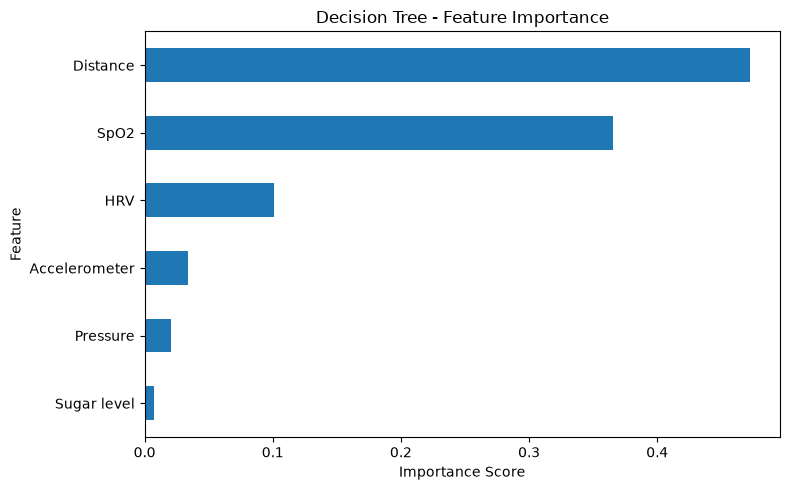

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

dt_importance = pd.Series(
    dt_model.feature_importances_,
    index=df_realistic.drop("Decision", axis=1).columns
).sort_values()

plt.figure(figsize=(8, 5))
dt_importance.plot(kind="barh")

plt.title("Decision Tree - Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [23]:

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_model


,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [24]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print(
    "Random Forest Accuracy:",
    round(accuracy_score(y_test, rf_pred) * 100, 2),
    "%"
)

Random Forest Accuracy: 96.81 %


In [25]:
from sklearn.metrics import classification_report

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.98      0.96      0.97       139
           1       0.99      0.96      0.97       137
           2       0.94      0.98      0.96       132

    accuracy                           0.97       408
   macro avg       0.97      0.97      0.97       408
weighted avg       0.97      0.97      0.97       408



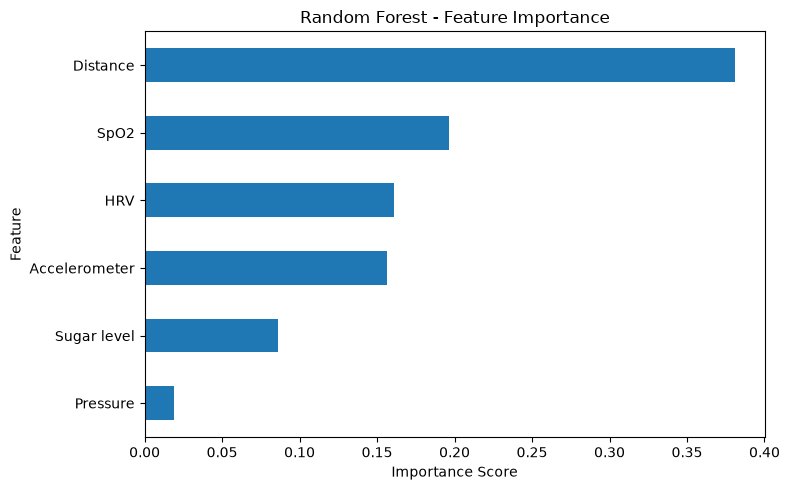

In [26]:
rf_importance = pd.Series(
    rf_model.feature_importances_,
    index=df_realistic.drop("Decision", axis=1).columns
).sort_values()

plt.figure(figsize=(8, 5))
rf_importance.plot(kind="barh")

plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [27]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

svm_model = make_pipeline(
    StandardScaler(),
    SVC()
)

svm_model.fit(X_train, y_train)

svm_model


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [28]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

svm_model = make_pipeline(
    StandardScaler(),
    SVC()
)

svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_test)

print(
    "SVM Accuracy:",
    round(accuracy_score(y_test, svm_pred) * 100, 2),
    "%"
)

SVM Accuracy: 96.32 %


In [29]:
print("SVM Classification Report")
print(classification_report(y_test, svm_pred))

SVM Classification Report
              precision    recall  f1-score   support

           0       0.98      0.96      0.97       139
           1       0.97      0.96      0.97       137
           2       0.94      0.96      0.95       132

    accuracy                           0.96       408
   macro avg       0.96      0.96      0.96       408
weighted avg       0.96      0.96      0.96       408



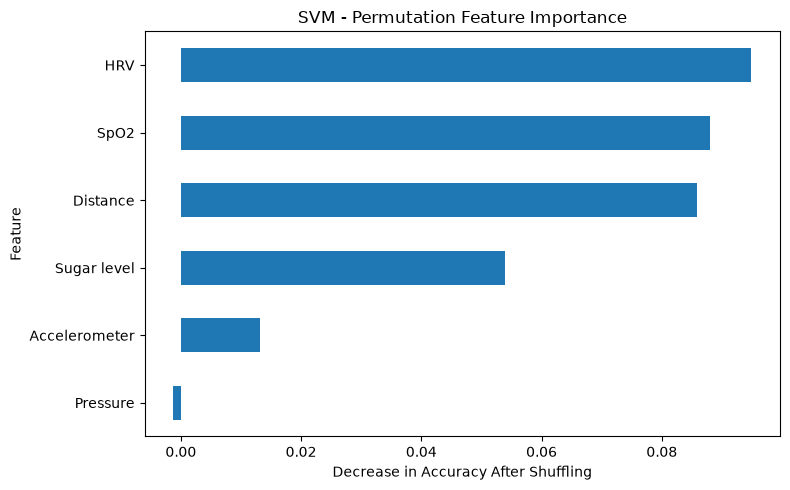

In [30]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Use the original feature names
feature_names = df_realistic.drop(
    "Decision", axis=1
).columns

# Calculate feature importance
svm_importance = permutation_importance(
    svm_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="accuracy"
)

# Create a graph
importance = pd.Series(
    svm_importance.importances_mean,
    index=feature_names
).sort_values()

plt.figure(figsize=(8, 5))
importance.plot(kind="barh")

plt.title("SVM - Permutation Feature Importance")
plt.xlabel("Decrease in Accuracy After Shuffling")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

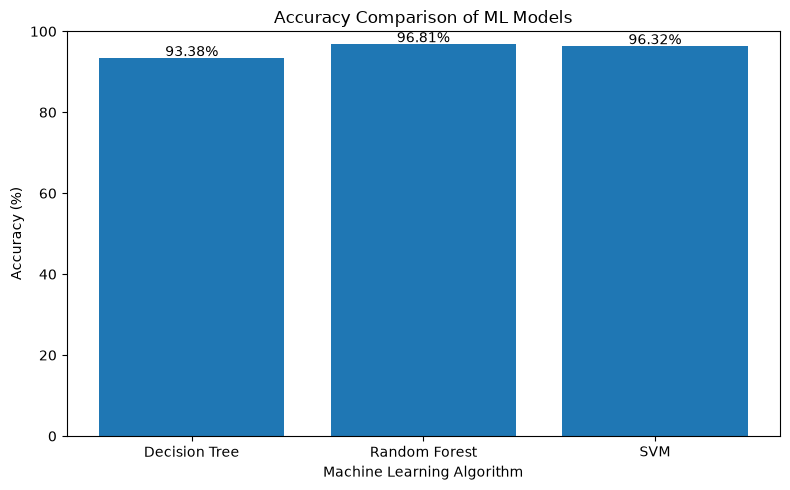

In [31]:
models = ["Decision Tree", "Random Forest", "SVM"]
accuracies = [
    accuracy_score(y_test, dt_pred) * 100,
    accuracy_score(y_test, rf_pred) * 100,
    accuracy_score(y_test, svm_pred) * 100
]

plt.figure(figsize=(8, 5))
plt.bar(models, accuracies)

plt.title("Accuracy Comparison of ML Models")
plt.xlabel("Machine Learning Algorithm")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for i, value in enumerate(accuracies):
    plt.text(i, value + 0.5, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

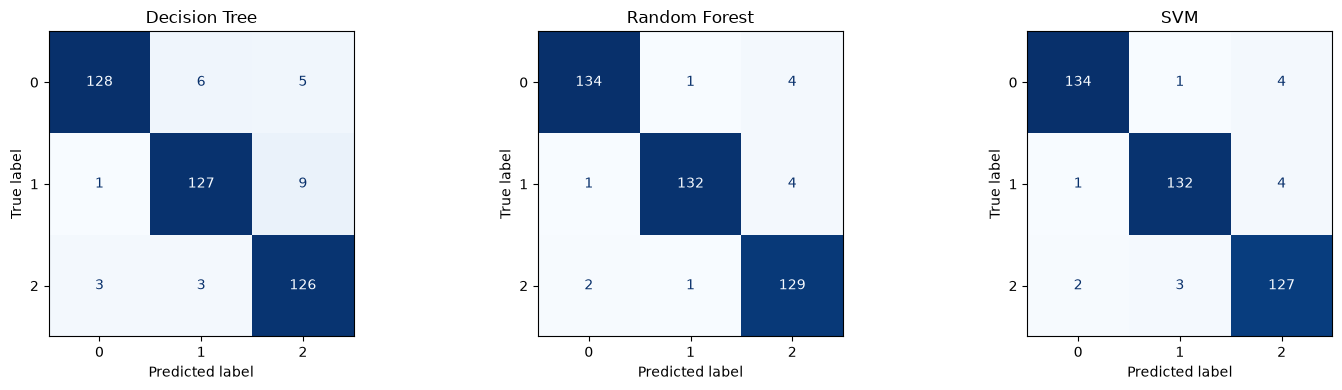

In [32]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

models = [
    ("Decision Tree", dt_pred),
    ("Random Forest", rf_pred),
    ("SVM", svm_pred)
]

for ax, (name, predictions) in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        ax=ax,
        cmap="Blues",
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

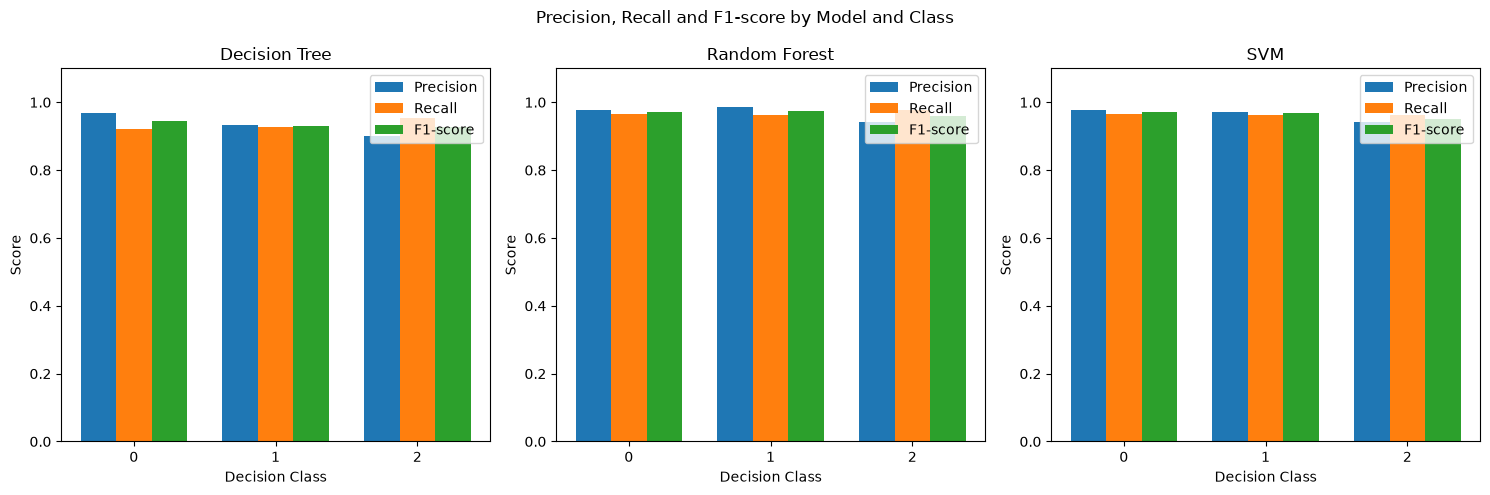

In [33]:
from sklearn.metrics import precision_recall_fscore_support
import numpy as np
import matplotlib.pyplot as plt

predictions = {
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "SVM": svm_pred
}

classes = sorted(y_test.unique())
metrics = ["Precision", "Recall", "F1-score"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (model_name, pred) in zip(axes, predictions.items()):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test,
        pred,
        labels=classes,
        zero_division=0
    )

    values = [precision, recall, f1]
    x = np.arange(len(classes))
    width = 0.25

    for i, (metric, scores) in enumerate(zip(metrics, values)):
        ax.bar(x + (i - 1) * width, scores, width, label=metric)

    ax.set_title(model_name)
    ax.set_xlabel("Decision Class")
    ax.set_ylabel("Score")
    ax.set_xticks(x)
    ax.set_xticklabels(classes)
    ax.set_ylim(0, 1.1)
    ax.legend()

plt.suptitle("Precision, Recall and F1-score by Model and Class")
plt.tight_layout()
plt.show()

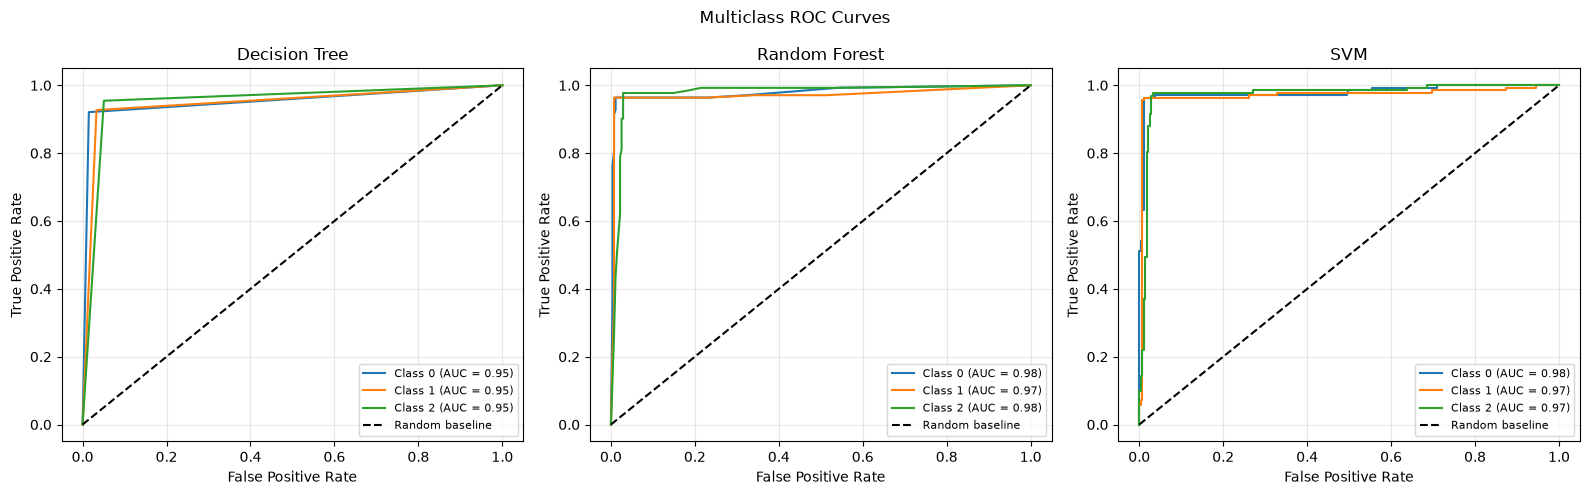

In [34]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

classes = sorted(y_test.unique())
y_test_binary = label_binarize(y_test, classes=classes)

# Get prediction scores from each model
dt_scores = dt_model.predict_proba(X_test)
rf_scores = rf_model.predict_proba(X_test)
svm_scores = svm_model.decision_function(X_test)

model_scores = {
    "Decision Tree": dt_scores,
    "Random Forest": rf_scores,
    "SVM": svm_scores
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (model_name, scores) in zip(axes, model_scores.items()):
    for i, class_label in enumerate(classes):
        fpr, tpr, _ = roc_curve(
            y_test_binary[:, i],
            scores[:, i]
        )

        roc_auc = auc(fpr, tpr)

        ax.plot(
            fpr,
            tpr,
            label=f"Class {class_label} (AUC = {roc_auc:.2f})"
        )

    ax.plot([0, 1], [0, 1], "k--", label="Random baseline")
    ax.set_title(model_name)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle("Multiclass ROC Curves")
plt.tight_layout()
plt.show()

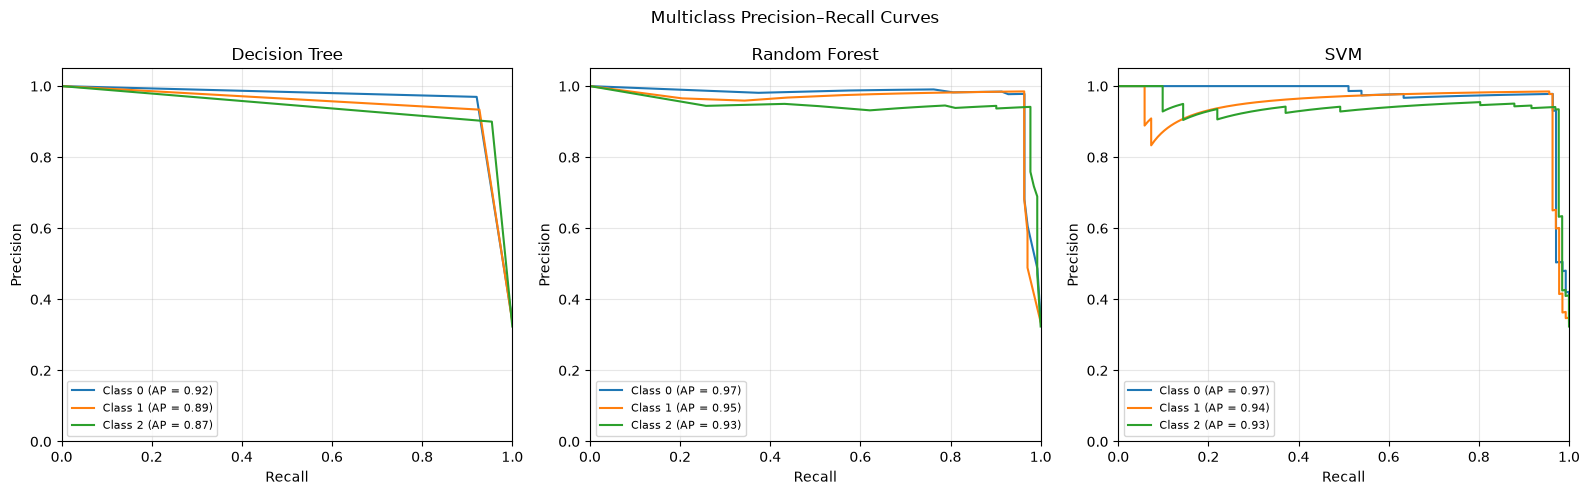

In [35]:
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

classes = sorted(y_test.unique())
y_test_binary = label_binarize(y_test, classes=classes)

model_scores = {
    "Decision Tree": dt_model.predict_proba(X_test),
    "Random Forest": rf_model.predict_proba(X_test),
    "SVM": svm_model.decision_function(X_test)
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (model_name, scores) in zip(axes, model_scores.items()):
    for i, class_label in enumerate(classes):
        precision, recall, _ = precision_recall_curve(
            y_test_binary[:, i],
            scores[:, i]
        )

        ap = average_precision_score(
            y_test_binary[:, i],
            scores[:, i]
        )

        ax.plot(
            recall,
            precision,
            label=f"Class {class_label} (AP = {ap:.2f})"
        )

    ax.set_title(model_name)
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle("Multiclass Precision–Recall Curves")
plt.tight_layout()
plt.show()

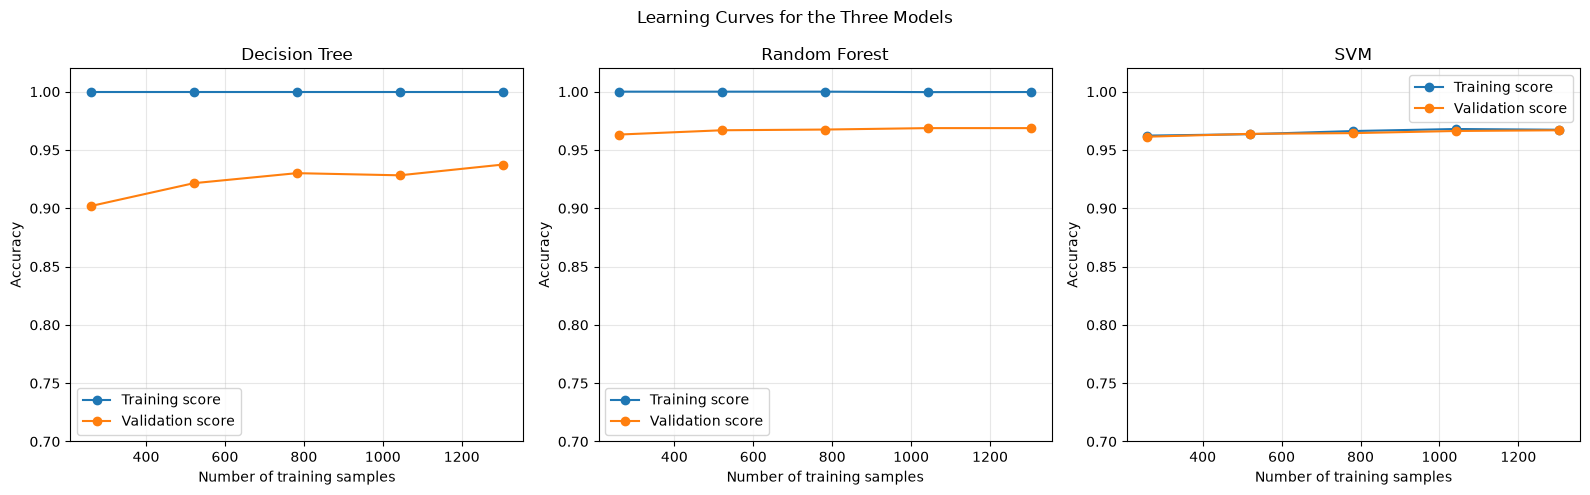

In [36]:
from sklearn.model_selection import learning_curve
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import numpy as np

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
    "SVM": make_pipeline(
        StandardScaler(),
        SVC()
    )
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, model) in zip(axes, models.items()):
    sizes, train_scores, val_scores = learning_curve(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy",
        train_sizes=np.linspace(0.2, 1.0, 5),
        shuffle=True,
        random_state=42,
        n_jobs=-1
    )

    ax.plot(
        sizes, train_scores.mean(axis=1),
        marker="o", label="Training score"
    )
    ax.plot(
        sizes, val_scores.mean(axis=1),
        marker="o", label="Validation score"
    )

    ax.set_title(name)
    ax.set_xlabel("Number of training samples")
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0.7, 1.02)
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle("Learning Curves for the Three Models")
plt.tight_layout()
plt.show()

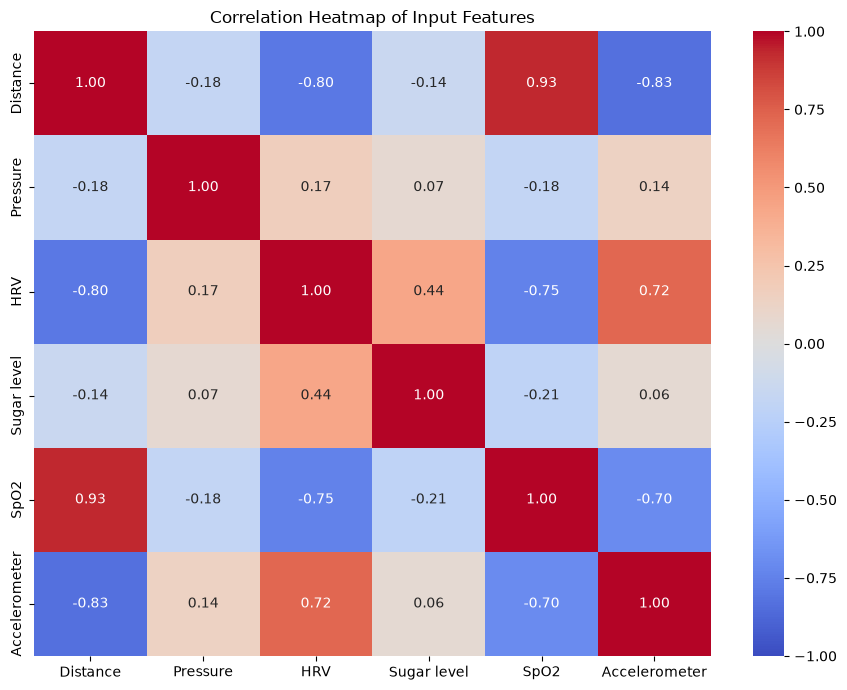

In [37]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    df_realistic.drop(columns="Decision").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Input Features")
plt.tight_layout()
plt.show()

## Conclusion and Final Model Selection

In this project, three machine learning algorithms—Decision Tree, Random Forest, and Support Vector Machine (SVM)—were implemented and evaluated for the Smart Fall Risk Detection task using the `cStick_realistic.csv` dataset.

The dataset was preprocessed by handling missing values through median imputation. The data was then divided into training and testing sets using an 80:20 split. The models were evaluated using accuracy, precision, recall, F1-score, confusion matrices, ROC curves, precision–recall curves, and learning curves.

The test results showed the following accuracies:

- **Decision Tree:** 93.38%
- **Random Forest:** 96.81%
- **Support Vector Machine (SVM):** 96.32%

Among the three models, **Random Forest achieved the highest test accuracy of 96.81%**. Therefore, it is selected as the final candidate model for the subsequent stages of this project.

The results demonstrate that machine learning can classify the decision categories present in the available dataset. However, accuracy alone does not guarantee reliable real-world fall detection. Further validation using independent, representative real-world data is necessary. The meanings of the target classes must also be confirmed from the dataset documentation before interpreting predictions as actual levels of fall risk.

### Future Scope

- Validate the selected model using independent real-world data.
- Investigate class-wise recall and misclassification patterns.
- Explore integration with real-time sensor data.
- Evaluate reliability and performance under practical conditions before deployment.

In conclusion, the Random Forest classifier is the best-performing model among the three algorithms evaluated in this experiment and will be used for further development and validation.

In [50]:

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Use training data only; keep the test set untouched
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Preprocessing is fitted separately inside each CV fold
models_cv = {
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ]),
    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC())
    ])
}

scoring = {
    "accuracy": "accuracy",
    "precision_weighted": "precision_weighted",
    "recall_weighted": "recall_weighted",
    "f1_weighted": "f1_weighted"
}

results = []

for name, pipeline in models_cv.items():
    scores = cross_validate(
        pipeline,
        X_train_raw,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "Accuracy (mean)": scores["test_accuracy"].mean(),
        "Accuracy (std)": scores["test_accuracy"].std(),
        "Precision (mean)": scores["test_precision_weighted"].mean(),
        "Recall (mean)": scores["test_recall_weighted"].mean(),
        "F1-score (mean)": scores["test_f1_weighted"].mean()
    })

cv_results = pd.DataFrame(results)

print("Five-Fold Cross-Validation Results")
display(cv_results.round(4))


Five-Fold Cross-Validation Results


,Model,Accuracy (mean),Accuracy (std),Precision (mean),Recall (mean),F1-score (mean)
0,Decision Tree,0.9240,0.0131,0.9246,0.9240,0.9239
1,Random Forest,0.9669,0.0066,0.9673,0.9669,0.9669
2,SVM,0.9663,0.0097,0.9667,0.9663,0.9662
